# Physics Informed Neural Networks and Deep Operator Network for beginners

#### by [Francisco Periago](https://multisimo.com/fpe/)

### Experiment 1: PINN approximation of the solution to the Laplace-Poisson equation

\begin{equation}
\left\{\begin{array}{ll}
-\Delta u(x) = -2d, & x\in D:=(0,1)^d \\
u(x) = \sum_{k=1}^d x_k^2, & x\in \partial D 
\end{array}
\right.
\end{equation}

This problem has the exact solution

\begin{equation}
u_{\text{exact}}(x) = \sum_{k=1}^d x_k^2
\end{equation}

Our implementation uses [Lu, Lu and Meng, Xuhui and Mao, Zhiping and Karniadakis, George Em.: DeepXDE: A deep learning library for solving differential equations. SIAM Review. 63(1), 208-228 (2021)](https://github.com/lululxvi/deepxde)

In [4]:
%pip install "numpy==1.26.4" "scipy<1.14.0" --force-reinstall --no-deps

  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
   ---------------------------------------- 0.0/45.9 MB ? eta -:--:--
   --- ------------------------------------ 4.5/45.9 MB 33.6 MB/s eta 0:00:02
   ----------- ---------------------------- 13.4/45.9 MB 39.8 MB/s eta 0:00:01
   --------------------- ------------------ 24.1/45.9 MB 44.8 MB/s eta 0:00:01
   ------------------------------- -------- 35.7/45.9 MB 47.2 MB/s eta 0:00:01
   ---------------------------------------  45.9/45.9 MB 47.8 MB/s eta 0:00:01
   ---------------------------------------- 45.9/45.9 MB 45.6 MB/s  0:00:01

  Attempting uninstall: scipy

    Found existing installation: scipy 1.17.1

    Uninstalling scipy-1.17.1:

   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 [scipy]
   ---------------------------------------- 0/2 

In [1]:
import deepxde as dde
import numpy as np
import matplotlib.pyplot as plt
#from deepxde.backend import tf

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


In [2]:
d = 2 # spatial dimension 

We define de Laplace-Poisson equation. Partial derivatives are computed by using [Automatic Differentation (AD)](https://www.jmlr.org/papers/volume18/17-468/17-468.pdf)

In [3]:
def pde(x, u): # Poisson's equation
    laplacian = sum(dde.grad.hessian(u, x, i=k, j=k) for k in range(d))
    return - laplacian + 2 * d
    
#we define the partial differential equation here. In the orginal problem, we try to minimize the residual of the PD

Let's define the geometry. In this case, it corresponds to the unit square $(0,1)^d$.

In [5]:
geom = dde.geometry.Hypercube([0] * d, [1] * d)

#bottom left corner and right corner

Next, we introduce the boundary conditions. For more details see [geometry_nd.py](https://github.com/lululxvi/deepxde/blob/master/deepxde/geometry/geometry_nd.py) 

In [6]:
# Helps to tell us if a point is in the boundary or not. 
#How it works is that in the OG file(boundary) the function is binary and return 1 if point is in poundary and 0 otherwise
#Boundary condition: u(x) = sum x_k^2
def boundary(x, on_boundary):
    return on_boundary

def boundary_value(x): # This one essentially assigns the point to the boundary condition
    return np.sum(np.square(x), axis=1, keepdims=True)

# Boundary condition
bc = dde.icbc.DirichletBC(geom, boundary_value, boundary)


Now, we introduce the dataset. This is composed of the geometry, the partial differential equation, boundary conditions, number of sampling quasi-random points in the interior of the domain, number of quasi-random points on the boundary, and number of quasi-random points (in the interior domain) that are used to check accuracy when solving the PDE.

By default, the [Hammersley distribution](https://en.wikipedia.org/wiki/Low-discrepancy_sequence) is used to select training points. More details may be found in  [pde.py](https://github.com/lululxvi/deepxde/blob/master/deepxde/data/pde.py)

In [7]:
data = dde.data.PDE(geom, pde, bc, num_domain=100, num_boundary=40, num_test=100) #, train_distribution="Hammersley"

As an illustration we now plot the selected points for training and test.

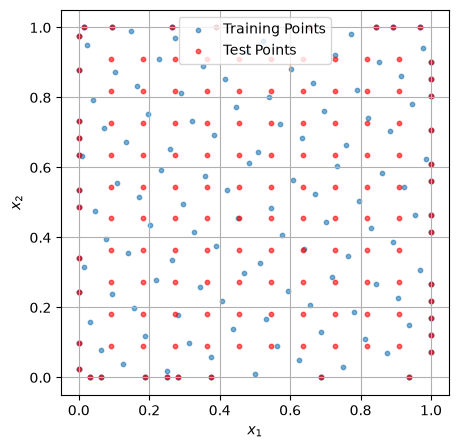

In [8]:
train_points = data.train_x  # Training points
test_points = data.test_x    # Test points ###

# Test points are use to calculate the generalization error. The algorithm does not see the test points during the training process

plt.figure(figsize=(5, 5))
plt.scatter(train_points[:, 0], train_points[:, 1], s=10, label='Training Points', alpha=0.6)
plt.scatter(test_points[:, 0], test_points[:, 1], s=10, label='Test Points', alpha=0.6, color='red')
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.legend()
plt.grid(True)
plt.show()

# if d=3 you may plot training and test points as follows:
#fig = plt.figure()
#ax = fig.add_subplot(111, projection='3d')
#ax.scatter(train_points[:, 0], train_points[:, 1], train_points[:, 2], s=10, label='Training Points', alpha=0.6)
#ax.scatter(test_points[:, 0], test_points[:, 1], test_points[:, 2], s=10, label='Test Points', alpha=0.6, color='red')
#plt.legend()
#plt.grid(True)
#plt.show()


Next step is to select a network architecture to be used to approximate the solution of the PDE. In this case, we choose a feed-forward neural network where the input layer has dimension $d$, there are two hidden layers with $50$ neurons each one. The output is an scalar. As suggested in [Sifan Wang, Shyam Sankaran, Hanwen Wang, Paris Perdikaris: An Expert's Guide to Training Physics-informed Neural Networks](https://arxiv.org/abs/2308.08468) and the references therein, the hyperbolic tangent is chosen as activation function for all layers. The initialization of the parameters of the network is carried out by following a [Glorot uniform distribution.](https://proceedings.mlr.press/v9/glorot10a/glorot10a.pdf)

In [9]:
net = dde.nn.FNN([d] + [50] * 3 + [1], "tanh", "Glorot uniform")

# Next step is to select the multilayer perceptron, and it is called the Feedforward Neural Network
# d is the input channel, in this specific problem, our input channel has d = 2
# The we take 3 hidden layers and 50 neurons in each layer
# The the output is a scaler quantity and it has an dimension of 1
# In all the layers, they take the hyperbolic tanget as the activation function
# And the initialization of the network parameters is taken according to the Glorot uniform distribution


Finally, we build the model, which is composed of data and net. 

The loss function is composed of the residuals for the initial, boundary conditions, and the PDE. Numerical integration is performed by computing the mean of the loss function evaluated at the training (and test) data.

The adaptive with moment algorithm (Adam) [Diederik P. Kingma, Jimmy Ba: Adam: A Method for Stochastic Optimization](https://arxiv.org/abs/1412.6980) is the optimizer of choice in deep learning, at least for the type of problems we are addressing here. The suggested learning rate is $lr=0.001$. Additionally, the weights for the PDE and boundary residuals may be selected. $1$ is the default value for all weights.

Compiling model...
'compile' took 3.247739 s

Training model...

Step      Train loss              Test loss               Test metric
0         [1.69e+01, 6.13e-01]    [1.70e+01, 6.13e-01]    []  
1000      [9.87e-04, 1.25e-03]    [8.50e-04, 1.25e-03]    []  
2000      [2.62e-03, 1.04e-02]    [1.91e-03, 1.04e-02]    []  
3000      [2.41e-04, 2.38e-04]    [2.66e-04, 2.38e-04]    []  
4000      [1.22e-04, 6.99e-05]    [1.10e-04, 6.99e-05]    []  
5000      [6.16e-05, 3.97e-05]    [5.36e-05, 3.97e-05]    []  
6000      [4.09e-05, 2.18e-05]    [3.63e-05, 2.18e-05]    []  
7000      [3.15e-05, 1.12e-05]    [2.77e-05, 1.12e-05]    []  
8000      [2.51e-05, 6.08e-06]    [2.24e-05, 6.08e-06]    []  
9000      [2.00e-05, 3.14e-06]    [1.80e-05, 3.14e-06]    []  
10000     [1.64e-05, 1.96e-06]    [1.48e-05, 1.96e-06]    []  

Best model at step 10000:
  train loss: 1.83e-05
  test loss: 1.68e-05
  test metric: []

'train' took 50.937447 s

Compiling model...
'compile' took 0.000351 s

Training 

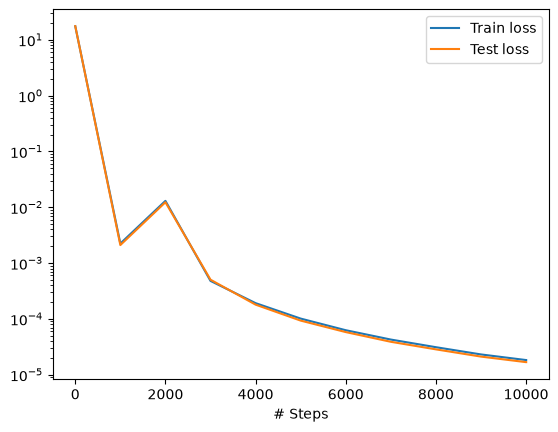

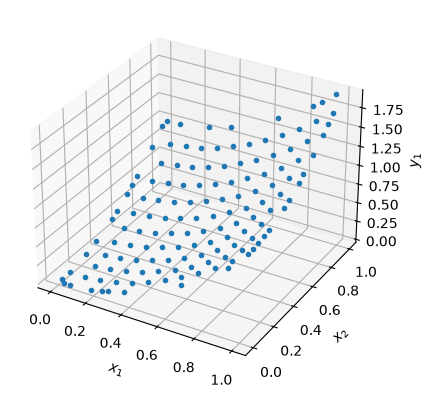

In [10]:
model = dde.Model(data, net)
model.compile("adam", lr=0.001, loss_weights=[1.0, 1.0]) # The weights for the contribution of the PDE and boundary residual 
model.train(iterations=10000)
model.compile("L-BFGS")
losshistory, train_state = model.train()
dde.saveplot(losshistory, train_state, issave=True, isplot=True)

Finally, we may compare the PINN and the exact solutions. 

In [11]:
# Predict
X = geom.uniform_points(1000)
y_pred = model.predict(X)
print(X.shape)

# Exact solution
y_exact = np.sum(X ** 2, axis=1, keepdims=True)

# Comparison
error = np.linalg.norm(y_pred - y_exact, 2) / np.linalg.norm(y_exact, 2)
print("Relative L2 error:", error)

(1024, 2)
Relative L2 error: 0.0013902065


And, graphycally for the case $d=2$

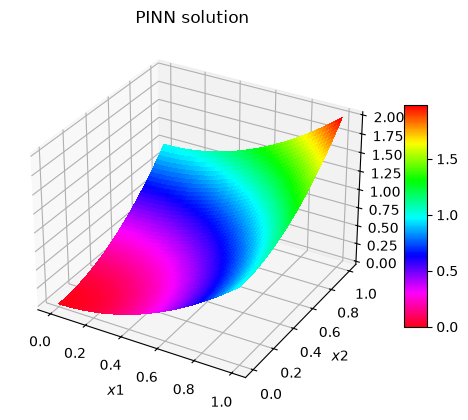

In [12]:
x_1 = np.linspace(0, 1, 100)
x_2 = np.linspace(0, 1, 100)
   
x_1_repeated = np.repeat(x_1,  x_2.shape[0])  # repeat each value of X the number of elements of t    
x_2_tiled = np.tile(x_2, x_1.shape[0]) # repeat the whole vector t, the number of elements of X    
xx = np.vstack((x_1_repeated, x_2_tiled)).T # stack them vertically and take the transpose
        
sol_predict = model.predict(xx).T # predicted solution
sol_predict_M = sol_predict.reshape((100,100)).T # predicted state in matrix form

x1, x2 = np.meshgrid(
    np.linspace(0, 1, 100),
    np.linspace(0, 1, 100)
    )

fig = plt.figure() # plot of predicted solution
ax = plt.axes(projection="3d")
surf = ax.plot_surface(x1, x2, sol_predict_M, 
                        cmap='hsv_r', linewidth=0, antialiased=False)

ax.set_title('PINN solution ')
ax.set_xlabel('$x1$')
ax.set_ylabel('$x2$')
fig.colorbar(surf, shrink=0.6, aspect=10)    
plt.show()

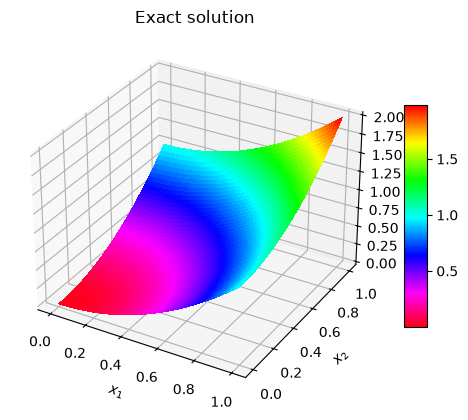

In [13]:

x1 = np.linspace(0, 1, 100)
x2 = np.linspace(0, 1, 100)
X1, X2 = np.meshgrid(x1, x2)

exact = X1**2 + X2**2 # exact solution

# Plot
fig = plt.figure() # plot of exact solution
ax = plt.axes(projection="3d")
surf_2 = ax.plot_surface(X1, X2, exact, cmap='hsv_r', linewidth=0, antialiased=False)

ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_zlabel('$y$')
ax.set_title('Exact solution')
fig.colorbar(surf_2, shrink=0.6, aspect=10) 
plt.show()